<a href="https://colab.research.google.com/github/soleildayana/Modern-Astrophysics/blob/main/ISM_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segundo Proyecto Computacional - Astrofísica Moderna
**Astronomía — Universidad de Antioquia (UdeA)**  
Soleil Dayana Niño Murcia

---

## Un modelo mínimo del medio interestelar galáctico: de los $\mu\text{m}$ a los $\text{kpc}$

En este proyecto construimos un modelo numérico de la radiación en el medio interestelar (ISM) desde primeros principios para analizar el presupuesto energético de la radiación en la Vía Láctea: desde la luz ultravioleta (UV) emitida por las estrellas masivas de tipo O hasta la radiación infrarroja (IR) reemitida térmicamente por los granos de polvo interestelar.

A pesar de abarcar más de 25 órdenes de magnitud en escala espacial (desde granos submicrométricos de $\sim 10^{-3}\text{--}10^{-1}\,\mu\text{m}$ hasta el disco galáctico de $R_{\text{gal}} = 36\,\text{kpc}$), veremos cómo aproximaciones de orden de magnitud permiten reproducir observaciones del ISM:
- El flujo del campo interestelar de radiación (ISRF) y la densidad de flujo de fotones UV ($\sim 10^8\text{ fotones cm}^{-2}\text{ s}^{-1}$).
- La temperatura de equilibrio del polvo interestelar ($T_g \approx 15\text{ K}$).
- La intensidad específica difusa en el infrarrojo lejano ($I_\nu \sim 10^{-13}\text{ erg s}^{-1}\text{ cm}^{-2}\text{ Hz}^{-1}\text{ sr}^{-1}$).
- La curva de extinción galáctica y la razón de extinción total a selectiva fiducial ($R_V \approx 3.1$).

In [1]:
# Librerías
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
from scipy.integrate import quad
from scipy.optimize import least_squares

from warnings import filterwarnings
filterwarnings('ignore')

# Semilla de aleatoriedad fija para reproducibilidad
rng = np.random.default_rng(42)

# Constantes físicas y astronómicas en cgs
kpc = 3.086e21       # cm
um = 1e-4            # cm (1 micrómetro)
sigma_sb = 5.67e-5   # erg cm^-2 s^-1 K^-4 (constante de Stefan-Boltzmann)
k_b = 1.38e-16       # erg K^-1 (constante de Boltzmann)
h = 6.626e-27        # erg s (constante de Planck)
c = 2.9979e10        # cm s^-1 (velocidad de la luz)
b_wien = 0.2898      # cm K (constante de desplazamiento de Wien)

## a. Distribución espacial de estrellas tipo O en el disco galáctico

La mayor parte de la radiación ultravioleta del campo interestelar proviene de las estrellas más masivas (tipo espectral O), cuya población en la Vía Láctea es aproximadamente $N_{O*} \approx 5 \times 10^4$, con una luminosidad individual típica $L_{O*} \approx 10^{40}\text{ erg s}^{-1}$.


Modelamos estas estrellas como distribuidas de forma aleatoria y **uniforme en área** sobre un disco bidimensional de radio $R_{\text{gal}} = 36\text{ kpc}$. Dado que el diferencial de área en coordenadas polares es $dA = r\,dr\,d\theta$, la densidad de probabilidad radial debe ser proporcional a $r$ ($P(r)\,dr \propto r\,dr$). Aplicando el método de la transformada inversa a partir de variables aleatorias uniformes $U_1, U_2 \sim \mathcal{U}(0, 1)$, obtenemos:

$$r = R_{\text{gal}}\sqrt{U_1}, \qquad \theta = 2\pi U_2$$

De esta forma se evita la acumulación artificial de estrellas hacia el centro galáctico que ocurriría si se muestreara linealmente como $r = R_{\text{gal}}U_1$.

In [2]:
# Parámetros galácticos en cgs
N_O = 5e4
L_O = 1e40               # erg s^-1
r_gal_kpc = 36.0         # kpc
r_gal = r_gal_kpc * kpc  # cm

In [3]:
def generar_galaxia(N, r_gal, rng=rng):
    """
    Genera posiciones cartesianas (x, y) de N estrellas distribuidas
    uniformemente en área dentro de un disco circular de radio r_gal.
    """
    u = rng.random(int(N))
    theta = rng.random(int(N)) * 2.0 * np.pi
    r = r_gal * np.sqrt(u)

    x = r * np.cos(theta)
    y = r * np.sin(theta)
    return x, y

In [4]:
# Generar distribución de estrellas (en cm) y puntos de medición sobre y = 0
x_estrellas, y_estrellas = generar_galaxia(N_O, r_gal)
x_med_kpc = np.arange(0.0, 36.1, 2.0)
x_med = x_med_kpc * kpc
y_med = np.zeros_like(x_med)

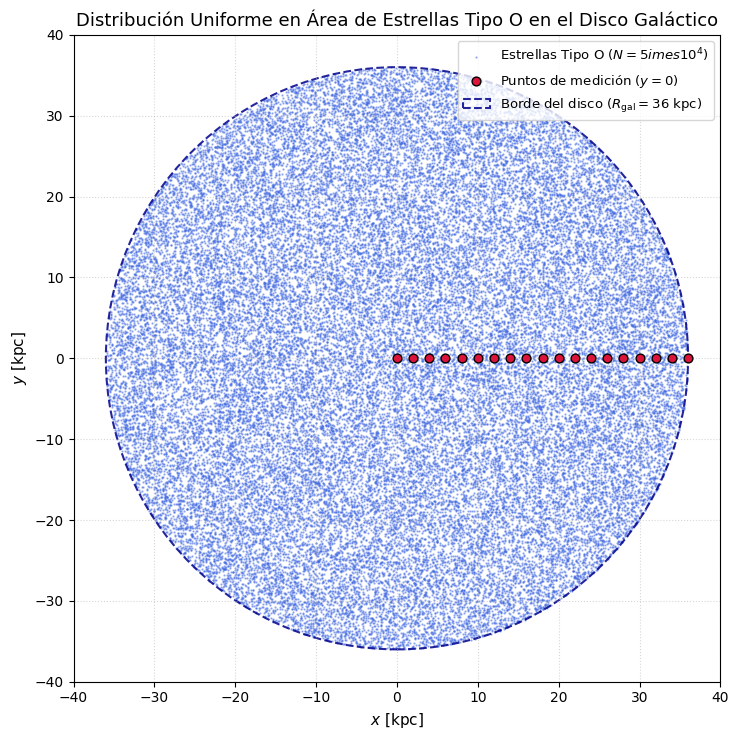

In [5]:
# Gráfica 2D (convirtiendo de cm a kpc para graficar)
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.scatter(x_estrellas / kpc, y_estrellas / kpc, s=0.5, color='royalblue',
           alpha=0.45, label='Estrellas Tipo O ($N = 5 \times 10^4$)')
ax.scatter(x_med_kpc, y_med / kpc, color='crimson', s=40, edgecolor='black',
           zorder=5, label='Puntos de medición ($y = 0$)')

anillo = plt.Circle((0, 0), r_gal_kpc, color='darkblue', fill=False,
                    linestyle='--', linewidth=1.5, alpha=0.85, label=r'Borde del disco ($R_{\mathrm{gal}} = 36$ kpc)')
ax.add_patch(anillo)

ax.set_title('Distribución Uniforme en Área de Estrellas Tipo O en el Disco Galáctico', fontsize=13)
ax.set_xlabel('$x$ [kpc]', fontsize=11)
ax.set_ylabel('$y$ [kpc]', fontsize=11)
ax.set_xlim(-40, 40)
ax.set_ylim(-40, 40)
ax.set_aspect('equal', adjustable='box')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right', fontsize=9.5)
plt.tight_layout()
plt.show()

## b. Flujo del campo interestelar de radiación ($F_{\text{ISM}}$) sin extinción

El flujo bolométrico total recibido en un punto de observación $\mathbf{r}_p = (x_p, y_p)$ se obtiene sumando la contribución de cada estrella según la ley del inverso del cuadrado:

$$F_{\text{ISM}}(\mathbf{r}_p) = \sum_{i=1}^{N_{O*}} \frac{L_{O*}}{4\pi d_i^2}, \qquad d_i = \sqrt{(x_i - x_p)^2 + (y_i - y_p)^2}$$

Dado que $F \propto d_i^{-2}$, si en una simulación aleatoria una estrella cae extremadamente cerca de un punto de medición, produce un pico artificial que no representa realmente el campo difuso promedio. Para mitigar esto, generamos $N_{\text{sim}} = 300$ realizaciones independientes de la galaxia y tomamos el **valor mínimo** de $F_{\text{ISM}}(r)$ en cada radio.

### Comparación con la solución analítica con corte físico
En el límite continuo, el disco tiene una densidad superficial constante $\Sigma = \frac{N_{O*}}{\pi R_{\text{gal}}^2}$, por lo que el flujo esperado a distancia radial $r$ del centro es:

$$F_{\text{analítico}}(r) = \int_0^{R_{\text{gal}}} \int_0^{2\pi} \frac{L_{O*}\,\Sigma}{4\pi \, d^2(r, r', \theta)} \, r'\,d\theta\,dr'$$

donde $d^2 = r^2 + r'^2 - 2rr'\cos\theta$. Para evitar la divergencia de $d \to 0$, introducimos un radio de corte inferior igual a la separación media entre estrellas en el disco: $d_{\min} = \Sigma^{-1/2} \approx 0.285\text{ kpc}$.

In [6]:
def flujo(r_punto, estrellas, a_ext=0.0):
    """
    Calcula el flujo recibido en r_punto = (x_p, y_p) [en cm] proveniente
    de todas las estrellas [en cm]. Retorna F_ISM en erg s^-1 cm^-2.
    Si a_ext > 0 [en mag kpc^-1], aplica la atenuación 10^(-0.4 * a_ext * d_kpc).
    """
    x_p, y_p = r_punto
    x_e, y_e = estrellas

    d_cm = np.sqrt((x_e - x_p)**2 + (y_e - y_p)**2)
    d_cm = np.maximum(d_cm, 1e-10 * kpc)  # Evita división exacta por cero

    flujos_individuales = L_O / (4.0 * np.pi * d_cm**2)
    if a_ext > 0.0:
        d_kpc = d_cm / kpc
        flujos_individuales *= 10.0**(-0.4 * a_ext * d_kpc)

    return np.sum(flujos_individuales)

In [7]:
# 1. Simulación Monte Carlo (300 realizaciones independientes)
num_simulaciones = 300
galaxias_simuladas = [generar_galaxia(N_O, r_gal) for _ in range(num_simulaciones)]

flujos_simulaciones = np.array([[flujo((r_p, 0.0), estrellas_sim, a_ext=0.0) for r_p in x_med]
                                for estrellas_sim in galaxias_simuladas])

F_ISM_min = np.min(flujos_simulaciones, axis=0)

# 2. Solución analítica integrada con corte físico d_min = 1 / sqrt(Sigma)
Sigma = N_O / (np.pi * r_gal**2) # cm^-2
d_min = 1.0 / np.sqrt(Sigma)  # cm

def integrando_analitico(theta, r_prime, r_obs):
    d2 = r_obs**2 + r_prime**2 - 2.0 * r_obs * r_prime * np.cos(theta)
    d2_safe = np.maximum(d2, d_min**2)
    return (L_O * Sigma / (4.0 * np.pi * d2_safe)) * r_prime

F_analitico = np.array([
    integrate.dblquad(integrando_analitico, 0.0, r_gal, 0.0, 2.0 * np.pi, args=(r_obs,))[0]
    for r_obs in x_med])

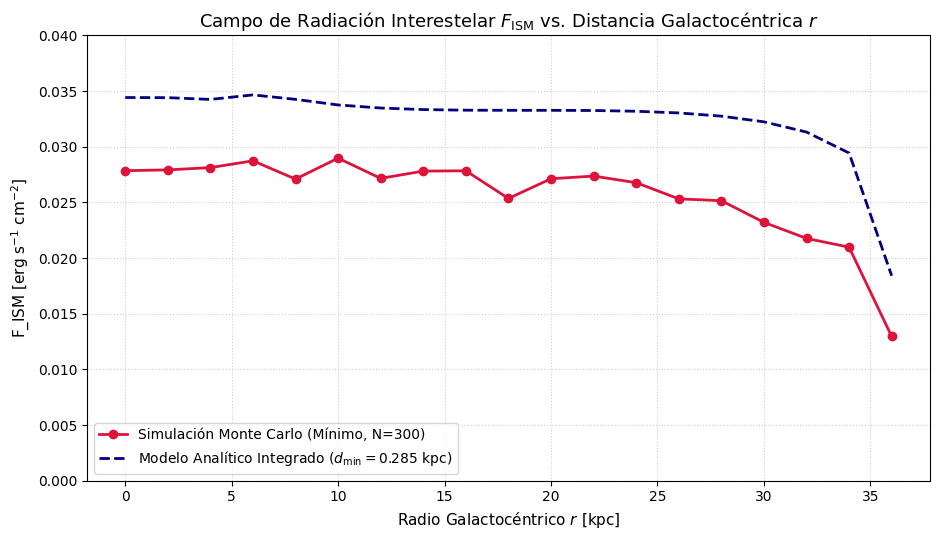

In [8]:
# Gráfica comparativa
plt.figure(figsize=(9.5, 5.5))
plt.plot(x_med_kpc, F_ISM_min, 'o-', color='crimson', linewidth=2,
         label=f'Simulación Monte Carlo (Mínimo, N={num_simulaciones})')
plt.plot(x_med_kpc, F_analitico, '--', color='navy', linewidth=2,
         label=f'Modelo Analítico Integrado ($d_{{\min}} = {d_min/kpc:.3f}$ kpc)')

plt.ylim(0, 0.04)
plt.title('Campo de Radiación Interestelar $F_{\mathrm{ISM}}$ vs. Distancia Galactocéntrica $r$', fontsize=13)
plt.xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
plt.ylabel('F_ISM [erg s$^{-1}$ cm$^{-2}$]', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='lower left')
plt.tight_layout()
plt.show()

Note que el perfil radial de $F_{\text{ISM}}(r)$ se mantiene aproximadamente constante ($\approx 2.8 \times 10^{-2}\text{ erg s}^{-1}\text{ cm}^{-2}$ en la simulación Monte Carlo y $\approx 3.4 \times 10^{-2}\text{ erg s}^{-1}\text{ cm}^{-2}$ en el modelo continuo) a lo largo de la mayor parte del disco interior ($r \lesssim 24\text{ kpc}$), y decae al alcanzar el borde del disco. Esto ocurre por simetría geométrica: en el borde de un disco uniforme, el observador solo recibe radiación desde un semiplano ($\Delta\theta = \pi$ en lugar de $2\pi$).

## c. Flujo del ISRF **con** extinción interestelar

En el medio interestelar real, el polvo absorbe y dispersa fuertemente la luz ultravioleta emitida por las estrellas tipo O. Incorporamos un coeficiente de extinción típico en el UV de $a_\lambda = 3.5\text{ mag kpc}^{-1}$, de modo que el flujo de cada estrella ubicada a una distancia $d$ (en $\text{kpc}$) se atenúa por el factor:

$$F_i = \frac{L_{O*}}{4\pi d_i^2} \, 10^{-0.4\, a_\lambda d_i} = \frac{L_{O*}}{4\pi d_i^2} \, e^{-\tau_\lambda}, \qquad \tau_\lambda = \frac{a_\lambda \, d_i}{1.086}$$

In [9]:
a_lambda = 3.5  # mag kpc^-1

# Simulación Monte Carlo con extinción usando las mismas simulaciones
flujos_extintos = np.array([
    [flujo((r_p, 0.0), estrellas_sim, a_ext=a_lambda) for r_p in x_med]
    for estrellas_sim in galaxias_simuladas
])
F_ISM_extintos = np.min(flujos_extintos, axis=0)

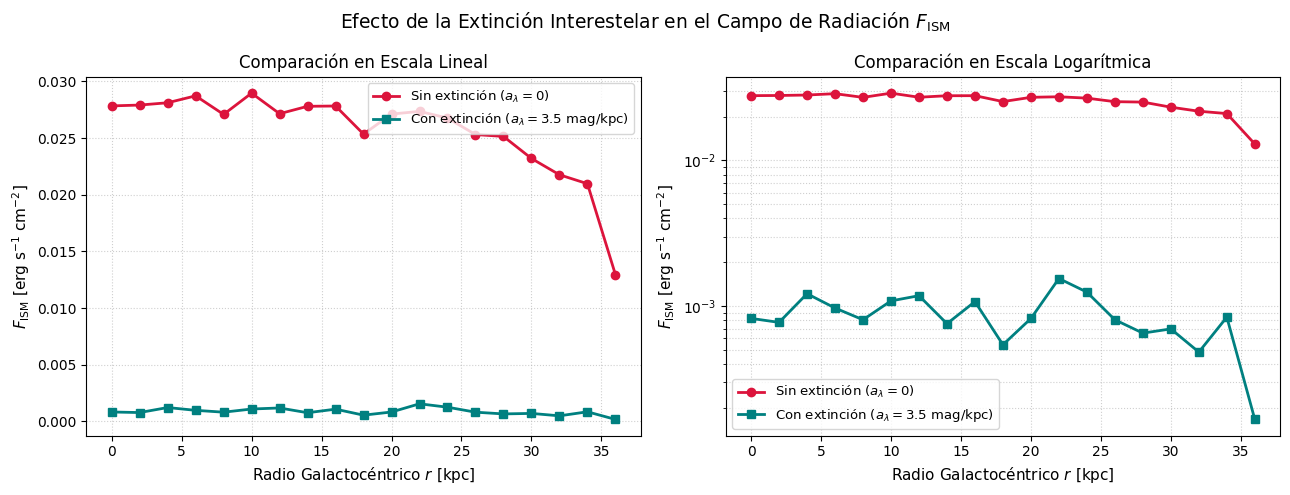

In [10]:
# Gráfica comparativa en escala lineal y logarítmica
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo: escala lineal (magnitud de la atenuación)
axes[0].plot(x_med_kpc, F_ISM_min, 'o-', color='crimson', linewidth=2, label='Sin extinción ($a_\lambda = 0$)')
axes[0].plot(x_med_kpc, F_ISM_extintos, 's-', color='teal', linewidth=2, label=f'Con extinción ($a_\lambda = {a_lambda}$ mag/kpc)')
axes[0].set_title('Comparación en Escala Lineal', fontsize=12)
axes[0].set_xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
axes[0].set_ylabel('$F_{\mathrm{ISM}}$ [erg s$^{-1}$ cm$^{-2}$]', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(fontsize=9.5, loc='upper right')

# Panel derecho: escala logarítmica (estructura radial con extinción)
axes[1].plot(x_med_kpc, F_ISM_min, 'o-', color='crimson', linewidth=2, label='Sin extinción ($a_\lambda = 0$)')
axes[1].plot(x_med_kpc, F_ISM_extintos, 's-', color='teal', linewidth=2, label=f'Con extinción ($a_\lambda = {a_lambda}$ mag/kpc)')
axes[1].set_yscale('log')
axes[1].set_title('Comparación en Escala Logarítmica', fontsize=12)
axes[1].set_xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
axes[1].set_ylabel('$F_{\mathrm{ISM}}$ [erg s$^{-1}$ cm$^{-2}$]', fontsize=11)
axes[1].grid(True, which='both', linestyle=':', alpha=0.6)
axes[1].legend(fontsize=9.5, loc='lower left')

fig.suptitle('Efecto de la Extinción Interestelar en el Campo de Radiación $F_{\mathrm{ISM}}$', fontsize=13.5)
plt.tight_layout()
plt.show()

In [11]:
# Cociente Flujo con vs sin extinción
ratio_flujo = F_ISM_min / F_ISM_extintos
ratio_flujo.mean()

np.float64(33.677941293819735)

Al incluir la extinción del polvo ($a_\lambda = 3.5\text{ mag kpc}^{-1}$), la profundidad óptica alcanza $\tau_\lambda = 1$ en apenas $d \approx 1.086 / 3.5 \approx 0.31\text{ kpc}$. Por tanto, solo las estrellas del vecindario cercano (de unos pocos cientos de pcs) contribuyen significativamente al campo de radiación en cada punto, disminuyendo el flujo $F_{\text{ISM}}$ en un factor $\sim 30$ (hasta $\sim 8 \times 10^{-4}\text{ erg s}^{-1}\text{ cm}^{-2}$).

## d. Densidad de flujo de fotones del ISRF

Considerando una temperatura efectiva típica $T_{O*} \approx 4 \times 10^4\text{ K}$ para las estrellas tipo O, la energía promedio de sus fotones y la longitud de onda característica asociada son:

$$\langle E \rangle \approx 2.7\, k_B T_{O*}, \qquad \lambda_{O*} = \frac{hc}{\langle E \rangle}$$

A partir de $\langle E \rangle$, el flujo numérico de fotones viene dado por $\Phi(r) = F_{\text{ISM}}(r) / \langle E \rangle$, que comparamos directamente con el valor observado en el medio interestelar local ($\Phi_{\text{obs}} \sim 10^8\text{ fotones cm}^{-2}\text{ s}^{-1}$).

In [12]:
T_O = 4e4          # K
Phi_obs = 1e8      # fotones cm^-2 s^-1 (valor observado en el ISM)

# Energía promedio del fotón y longitud de onda característica
E_prom = 2.7 * k_b * T_O      # erg
lam_O = h * c / E_prom        # cm

print(f'<E>       = {E_prom:.3e} erg ({E_prom / 1.602e-12:.2f} eV)')
print(f'lambda_O* = {lam_O:.3e} cm ({lam_O * 1e7:.1f} nm)')

# Flujo de fotones sin extinción (b) y con extinción (c)
Phi_b = F_ISM_min / E_prom
Phi_c = F_ISM_extintos / E_prom

print(f'Phi_sin_ext(r=0) = {Phi_b[0]:.2e} fotones cm^-2 s^-1  (Phi / Phi_obs = {Phi_b[0]/Phi_obs:.1f})')
print(f'Phi_con_ext(r=0) = {Phi_c[0]:.2e} fotones cm^-2 s^-1  (Phi / Phi_obs = {Phi_c[0]/Phi_obs:.2f})')

<E>       = 1.490e-11 erg (9.30 eV)
lambda_O* = 1.333e-05 cm (133.3 nm)
Phi_sin_ext(r=0) = 1.87e+09 fotones cm^-2 s^-1  (Phi / Phi_obs = 18.7)
Phi_con_ext(r=0) = 5.51e+07 fotones cm^-2 s^-1  (Phi / Phi_obs = 0.55)


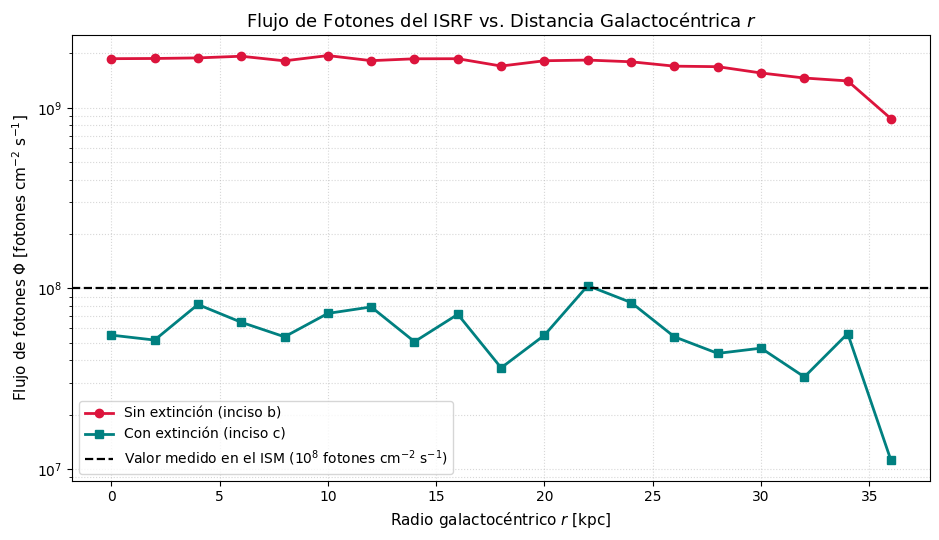

In [13]:
# Gráfica comparativa
plt.figure(figsize=(9.5, 5.5))
plt.plot(x_med_kpc, Phi_b, 'o-', color='crimson', linewidth=2, label='Sin extinción (inciso b)')
plt.plot(x_med_kpc, Phi_c, 's-', color='teal', linewidth=2, label='Con extinción (inciso c)')
plt.axhline(Phi_obs, color='black', linestyle='--', linewidth=1.6,
            label=r'Valor medido en el ISM ($10^8$ fotones cm$^{-2}$ s$^{-1}$)')

plt.yscale('log')
plt.xlabel('Radio galactocéntrico $r$ [kpc]', fontsize=11)
plt.ylabel(r'Flujo de fotones $\Phi$ [fotones cm$^{-2}$ s$^{-1}$]', fontsize=11)
plt.title('Flujo de Fotones del ISRF vs. Distancia Galactocéntrica $r$', fontsize=13)
plt.legend(fontsize=10)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

**Comparación con las observaciones:**  
Los fotones característicos tienen energía correspondiente a $\lambda_{O*} \approx 133.3\text{ nm}$ en el ultravioleta lejano. Sin extinción, el modelo sobreestima el flujo de fotones observado en casi un orden de magnitud. Al incorporar la extinción por polvo interestelar, el flujo desciende a $\Phi \sim (5\text{--}10) \times 10^7\text{ fotones cm}^{-2}\text{ s}^{-1}$, coincidiendo al fin con el orden de magnitud medido en la Vía Láctea ($\sim 10^8\text{ fotones cm}^{-2}\text{ s}^{-1}$).

## e. Temperatura de equilibrio térmico del polvo ($T_g$)

Los granos de polvo interestelar (de radio típico $a \approx 0.1\,\mu\text{m} = 10^{-5}\text{ cm}$) absorben la radiación UV del campo interestelar ($F_{\text{abs}} = F_{\text{ISM}}$) y la reemiten térmicamente en el infrarrojo lejano. Debido a que su tamaño es mucho menor que la longitud de onda de emisión ($\lambda_g > 2\pi a$), no emiten como cuerpos negros ideales, sino modulados por la eficiencia de emisión de Mie $Q_{\lambda_g} = (2\pi a / \lambda_g)^\beta$ con $\beta = 1.45$:

$$F_{\text{em}} = \sigma_{\text{SB}} T_g^4 \, Q_{\lambda_g} = \sigma_{\text{SB}} T_g^4 \left(\frac{2\pi a}{\lambda_g}\right)^\beta$$

Sustituyendo el pico de emisión dado por la ley de Wien, $\lambda_g = b_W / T_g$, e imponiendo equilibrio radiativo ($F_{\text{em}} = F_{\text{ISM}}(r)$), despejamos la temperatura de equilibrio $T_g(r)$:

$$\sigma_{\text{SB}} \left(\frac{2\pi a}{b_W}\right)^\beta T_g^{4+\beta} = F_{\text{ISM}}(r) \quad \Longrightarrow \quad T_g(r) = \left[\frac{F_{\text{ISM}}(r)}{\sigma_{\text{SB}} \left(2\pi a / b_W\right)^\beta}\right]^{\frac{1}{4+\beta}}$$

In [14]:
beta = 1.45
a_grano = 0.1 * um  # 0.1 micrómetros = 1e-5 cm

def temperatura_polvo(F_ISM, a_cm=a_grano, beta=beta):
    """
    Calcula la temperatura de equilibrio radiativo T_g [K] de granos de polvo
    de radio a_cm [cm] bajo un campo de radiación F_ISM [erg s^-1 cm^-2].
    """
    factor_mie = (2.0 * np.pi * a_cm / b_wien)**beta
    return (F_ISM / (sigma_sb * factor_mie))**(1.0 / (4.0 + beta))

T_g = temperatura_polvo(F_ISM_extintos)
Tg_mean = np.mean(T_g)
Tg_mean

np.float64(15.373181757802232)

In [15]:
# Verificación de la condición de validez de la aproximación de Mie: lambda_g > 2*pi*a
pi2a = 2.0 * np.pi * a_grano
lambda_g_perfil = b_wien / T_g

print(f'T_g promedio galáctico = {Tg_mean:.2f} K  (rango: {np.min(T_g):.2f} K – {np.max(T_g):.2f} K)\n \n')
print(f'2*pi*a           = {pi2a:.3e} cm ({pi2a / um:.3f} um)')
print(f'lambda_g promedio    = {np.mean(lambda_g_perfil):.3e} cm ({np.mean(lambda_g_perfil) / um:.1f} um)')
print(f'¿Se cumple lambda_g > 2*pi*a en todos los radios?: {np.all(lambda_g_perfil > pi2a)}')

T_g promedio galáctico = 15.37 K  (rango: 11.50 K – 17.30 K)
 

2*pi*a           = 6.283e-05 cm (0.628 um)
lambda_g promedio    = 1.899e-02 cm (189.9 um)
¿Se cumple lambda_g > 2*pi*a en todos los radios?: True


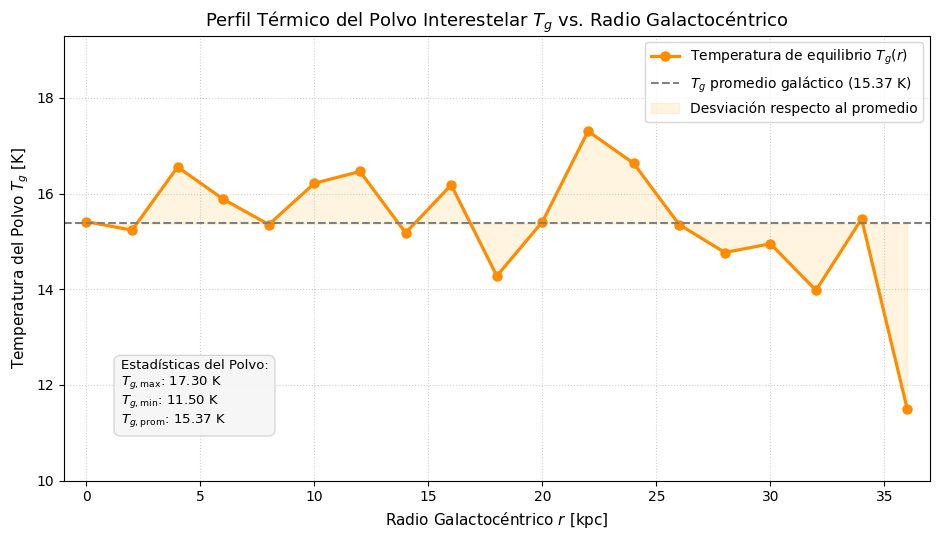

In [16]:
# Gráfica del perfil térmico del polvo
plt.figure(figsize=(9.5, 5.5))
plt.plot(x_med_kpc, T_g, 'o-', color='darkorange', linewidth=2.3, markersize=6.5,
         label='Temperatura de equilibrio $T_g(r)$')
plt.axhline(Tg_mean, color='gray', linestyle='--', linewidth=1.5,
            label=f'$T_g$ promedio galáctico ({Tg_mean:.2f} K)')
plt.fill_between(x_med_kpc, T_g, Tg_mean, color='orange', alpha=0.12,
                 label='Desviación respecto al promedio')

stats_text = (
    f'Estadísticas del Polvo:\n'
    f'$T_{{g,\max}}$: {np.max(T_g):.2f} K\n'
    f'$T_{{g,\min}}$: {np.min(T_g):.2f} K\n'
    f'$T_{{g,\mathrm{{prom}}}}$: {Tg_mean:.2f} K'
)
plt.text(1.5, np.min(T_g) - 0.3, stats_text, fontsize=9.5,
         bbox=dict(boxstyle='round,pad=0.5', facecolor='whitesmoke', alpha=0.9, edgecolor='lightgray'))

plt.ylim(np.min(T_g) - 1.5, np.max(T_g) + 2.0)
plt.xlim(-1, 37)
plt.title('Perfil Térmico del Polvo Interestelar $T_g$ vs. Radio Galactocéntrico', fontsize=13)
plt.xlabel('Radio Galactocéntrico $r$ [kpc]', fontsize=11)
plt.ylabel('Temperatura del Polvo $T_g$ [K]', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

La temperatura de equilibrio del polvo resulta en un promedio de $T_{g,\text{prom}} \approx 15.4\text{ K}$ (variando entre $\sim 17.3\text{ K}$ en el disco interior y $\sim 11.5\text{ K}$ en el borde exterior). Esto coincide con las temperaturas observadas en nubes interestelares y nubes moleculares ($10\text -  20\text{ K}$). La débil dependencia de $T_g$ respecto a las variaciones de flujo se explica por el exponente $1/(4+\beta) = 1/5.45 \approx 0.183$: un cambio de un factor $2$ en el flujo $F_{\text{ISM}}$ modifica $T_g$ en apenas un $\sim 13\%$.

## f. Coeficiente de extinción en el infrarrojo lejano ($\lambda_g$)

Para granos esféricos de radio $a = 0.1\,\mu\text{m}$ y densidad numérica $n_d = 3.5 \times 10^{-10}\text{ cm}^{-3}$, el coeficiente lineal de extinción $\kappa_{\lambda_g}$ y el coeficiente en magnitudes por kiloparsec $a_{\lambda_g}$ en la longitud de onda pico $\lambda_g = b_W / T_{g,\text{prom}}$ son:

$$\kappa_{\lambda_g} = n_d \, \pi a^2 \, Q_{\lambda_g}, \qquad a_{\lambda_g} = 1.086 \, \kappa_{\lambda_g} \, (1\text{ kpc})$$

In [17]:
n_d = 3.5e-10  # cm^-3

lambda_g = b_wien / Tg_mean                        # cm
Q_g = (2.0 * np.pi * a_grano / lambda_g)**beta     # Eficiencia de Mie en lambda_g
kappa_g = n_d * np.pi * a_grano**2 * Q_g           # cm^-1
a_lambda_g = 1.086 * kappa_g * kpc                 # mag kpc^-1

print(f'lambda_g   = {lambda_g:.3e} cm ({lambda_g / um:.1f} um)')
print(f'Q_g        = {Q_g:.3e}')
print(f'kappa_g    = {kappa_g:.3e} cm^-1')
print(f'a_lambda_g = {a_lambda_g:.4f} mag kpc^-1  (vs. a_UV = {a_lambda} mag kpc^-1)')

lambda_g   = 1.885e-02 cm (188.5 um)
Q_g        = 2.559e-04
kappa_g    = 2.814e-23 cm^-1
a_lambda_g = 0.0943 mag kpc^-1  (vs. a_UV = 3.5 mag kpc^-1)


**¿Por qué $a_{\lambda_g}$ es mucho menor que el coeficiente usado en el punto c?**  
En el ultravioleta ($\lambda_{O*} \approx 0.133\,\mu\text{m}$), la longitud de onda es menor que el perímetro del grano ($\lambda_{O*} < 2\pi a \approx 0.628\,\mu\text{m}$), por lo que la radiación interactúa en su máxima eficiencia ($Q_{\text{UV}} \sim 1$) y produce una extinción elevada ($a_{\lambda_{O*}} = 3.5\text{ mag kpc}^{-1}$).

En cambio, el polvo reemite su energía en el infrarrojo lejano ($\lambda_g \approx 188\,\mu\text{m} \gg 2\pi a$), donde los granos son mucho más pequeños que la longitud de onda de la radiación; en este régimen de Mie/Rayleigh la eficiencia cae drásticamente según $Q_{\lambda_g} = (2\pi a / \lambda_g)^{1.45} \approx 2.6 \times 10^{-4}$, reduciendo el coeficiente de extinción en casi dos órdenes de magnitud ($a_{\lambda_g} \approx 0.094\text{ mag kpc}^{-1}$).

## g. Intensidad específica emergente ($I_\nu$) en el centro galáctico

Asumiendo que el polvo emite y absorbe térmicamente en equilibrio termodinámico local con función fuente dada por la ley de Planck, $S_\nu = B_\nu(T_{g,\text{prom}})$ a frecuencia $\nu_g = c / \lambda_g$, la solución formal de la ecuación de transferencia radiativa a lo largo de una columna de longitud $R_{\text{gal}} = 36\text{ kpc}$ desde el borde hasta el centro geométrico de la galaxia es:

$$I_{\nu_g} = B_{\nu_g}(T_g)\left(1 - e^{-\tau_g}\right), \qquad \tau_g = \kappa_{\lambda_g} R_{\text{gal}} = \left(\frac{a_{\lambda_g}}{1.086}\right) R_{\text{gal, kpc}}$$

In [18]:
nu_g = c / lambda_g  # Hz

# Función de Planck B_nu(T_g) en erg s^-1 cm^-2 Hz^-1 sr^-1
S_nu = (2.0 * h * nu_g**3 / c**2) / np.expm1(h * nu_g / (k_b * Tg_mean))

# Espesor óptico desde el centro hasta el radio galáctico (36kpc)
tau_g = (a_lambda_g / 1.086) * r_gal_kpc

# Solución de la ecuación de transferencia radiativa
I_nu = S_nu * (1.0 - np.exp(-tau_g))

print(f'Frecuencia nu_g       = {nu_g:.3e} Hz')
print(f'Espesor óptico tau_g  = {tau_g:.3f}')
print(f'Función fuente S_nu   = {S_nu:.3e} erg s^-1 cm^-2 Hz^-1 sr^-1')
print(f'Intensidad emergente  = {I_nu:.3e} erg s^-1 cm^-2 Hz^-1 sr^-1')

Frecuencia nu_g       = 1.590e+12 Hz
Espesor óptico tau_g  = 3.126
Función fuente S_nu   = 4.159e-13 erg s^-1 cm^-2 Hz^-1 sr^-1
Intensidad emergente  = 3.977e-13 erg s^-1 cm^-2 Hz^-1 sr^-1



1. **¿Es ópticamente delgado el polvo en $\lambda_g$?** A lo largo del trayecto completo en el plano del disco desde el borde hasta el centro ($R_{\text{gal}} = 36\text{ kpc}$), el espesor óptico integrado es $\tau_g \approx 3.1 > 1$, por lo que la columna completa del plano galáctico es **ópticamente gruesa** (a diferencia de direcciones perpendiculares al disco o distancias locales $\lesssim 11\text{ kpc}$, donde $\tau < 1$ es ópticamente delgado).  
2. **Comparación con observaciones:** La intensidad emergente obtenida es $I_\nu \approx 4.0 \times 10^{-13}\text{ erg s}^{-1}\text{ cm}^{-2}\text{ Hz}^{-1}\text{ sr}^{-1}$, valor que coincide en orden de magnitud (apenas un factor 4 por encima) con la intensidad difusa infrarroja medida en la Vía Láctea ($\sim 10^{-13}\text{ erg s}^{-1}\text{ cm}^{-2}\text{ Hz}^{-1}\text{ sr}^{-1}$).

## h. Modelo realista de polvo: distribución de tamaños MRN

En lugar de granos de un único tamaño, consideramos una distribución continua de radios $a \in [a_{\min}, a_{\max}]$ siguiendo una ley de potencias (modelo MRN):

$$\frac{dn_d}{da} = C\, a^{-3.5}$$

Imponiendo que la integral sobre todos los tamaños recupere la densidad numérica total $n_d$, obtenemos la constante de normalización $C$:

$$n_d = \int_{a_{\min}}^{a_{\max}} C\, a^{-3.5}\,da = \frac{C}{2.5}\left(a_{\min}^{-2.5} - a_{\max}^{-2.5}\right) \quad \Longrightarrow \quad C = \frac{2.5\, n_d}{a_{\min}^{-2.5} - a_{\max}^{-2.5}}$$

Integrando la sección eficaz $\sigma_{\text{ext}}(a, \lambda) = \pi a^2 Q_\lambda(a)$ sobre la población de granos, el coeficiente de extinción total es:

$$\kappa_\lambda^{\text{ext}} = \pi C \int_{a_{\min}}^{a_{\max}} Q_\lambda(a)\, a^{-1.5}\,da, \qquad Q_\lambda(a) = \begin{cases} 1 & \text{si } \lambda \le 2\pi a \\ \left(\dfrac{2\pi a}{\lambda}\right)^\beta & \text{si } \lambda > 2\pi a \end{cases}$$

### Metodología Computacional del Modelo MRN

Para simular de manera realista el polvo interestelar, implementamos la distribución de tamaños de Mathis, Rumpl y Nordsieck (MRN), la cual describe una población de granos de polvo esféricos cuyos radios siguen una ley de potencias $dn_d/da = C a^{-3.5}$ en el intervalo $[a_{\min}, a_{\max}]$.

El flujo de trabajo se estructura en los siguientes pasos:

1. **Normalización de la Distribución ($C$):**
   Dado que conocemos la densidad numérica total de granos de polvo ($n_d = 3.5 \times 10^{-10}\text{ cm}^{-3}$), determinamos la constante de normalización $C$ integrando analíticamente la distribución:
   $$n_d = \int_{a_{\min}}^{a_{\max}} C a^{-3.5}\,da \quad \Longrightarrow \quad C = \frac{2.5\,n_d}{a_{\min}^{-2.5} - a_{\max}^{-2.5}}$$

2. **Integración Numérica de la Extinción (Sub-régimen de Mie):**
   La sección eficaz de extinción de un grano es $\sigma_{\text{ext}} = \pi a^2 Q_{\lambda}(a)$. El coeficiente de extinción lineal $\kappa_\lambda$ se obtiene integrando sobre todos los tamaños de grano:
   $$\kappa_\lambda = \int_{a_{\min}}^{a_{\max}} \pi a^2 Q_\lambda(a) \frac{dn_d}{da}\,da = \pi C \int_{a_{\min}}^{a_{\max}} Q_\lambda(a) a^{-1.5}\,da$$\n   La eficiencia $Q_\lambda(a)$ cambia de régimen abruptamente en el tamaño crítico $a_{\text{crit}} = \lambda / (2\pi)$. Para garantizar la precisión numérica del integrando, empleamos la función `scipy.integrate.quad` especificando `points=[a_crit]` para manejar adecuadamente la discontinuidad en la derivada de la función por trozos.

3. **Optimización No Lineal por Mínimos Cuadrados:**
   Buscamos determinar los límites de tamaño óptimos ($a_{\min}, a_{\max}$) que minimicen las desviaciones respecto a los parámetros observacionales fiduciales de la Vía Láctea:
   - Extinción en la banda V ($a_V = 1.0\text{ mag kpc}^{-1}$)
   - Extinción en el UV para estrellas tipo O ($a_{\lambda_{O*}} = 3.5\text{ mag kpc}^{-1}$)
   - Razón de extinción total a selectiva ($R_V = a_V / (a_B - a_V) = 3.1$)

   Para asegurar que los tamaños de grano físicos se mantengan siempre positivos durante la convergencia y manejar órdenes de magnitud muy amplios, definimos el vector de parámetros en espacio logarítmico $\mathbf{p} = [\ln a_{\min}, \ln a_{\max}]$. Definimos la función de residuos como la diferencia logarítmica:
   $$\mathbf{R}(\mathbf{p}) = \begin{bmatrix} \ln(a_V / 1.0) \\ \ln(R_V / 3.1) \\ \ln(a_{\lambda_{O*}} / 3.5) \end{bmatrix}$$
   y resolvemos utilizando el algoritmo de mínimos cuadrados con cotas de caja (`scipy.optimize.least_squares`).

In [19]:
# Longitudes de onda características en micrómetros
lambda_B = 0.44             # Banda B (azul)
lambda_V = 0.55             # Banda V (visual)
lambda_O_um = lam_O / um    # Longitud de onda característica de estrellas O (~0.133 um)

def normalizacion_MRN(a_min_um, a_max_um):
    """Calcula la constante de normalización C en unidades cgs."""
    a_min = a_min_um * um
    a_max = a_max_um * um
    return (2.5 * n_d) / (a_min**(-2.5) - a_max**(-2.5))

def Q_ext(a_cm, lambda_cm):
    """Eficiencia de extinción de Mie según el régimen de tamaño."""
    if lambda_cm <= 2.0 * np.pi * a_cm:
        return 1.0
    return (2.0 * np.pi * a_cm / lambda_cm)**beta

def coeficiente_extincion(lambda_um, a_min_um, a_max_um):
    """Calcula a_lambda [mag kpc^-1] integrando sobre la distribución MRN."""
    a_min = a_min_um * um
    a_max = a_max_um * um
    lam = lambda_um * um
    C = normalizacion_MRN(a_min_um, a_max_um)

    # Punto de transición de régimen a_crit = lambda / (2*pi) para integración precisa
    a_crit = lam / (2.0 * np.pi)
    puntos_corte = [a_crit] if (a_min < a_crit < a_max) else []

    integrando = lambda a: np.pi * C * a**(-1.5) * Q_ext(a, lam)
    kappa, _ = quad(integrando, a_min, a_max, points=puntos_corte, limit=100)
    return 1.086 * kappa * kpc

def parametros_extincion(a_min_um, a_max_um):
    a_B = coeficiente_extincion(lambda_B, a_min_um, a_max_um)
    a_V = coeficiente_extincion(lambda_V, a_min_um, a_max_um)
    a_O = coeficiente_extincion(lambda_O_um, a_min_um, a_max_um)
    R_V = a_V / (a_B - a_V)
    return a_B, a_V, a_O, R_V

def residuos(parametros):
    a_min_um, a_max_um = np.exp(parametros)
    _, a_V, a_O, R_V = parametros_extincion(a_min_um, a_max_um)
    return np.array([
        np.log(a_V / 1.0),
        np.log(R_V / 3.1),
        np.log(a_O / 3.5)
    ])

In [20]:
# Optimización
iniciales = np.log([1e-3, 1e-1])
limites = (np.log([1e-5, 1e-2]), np.log([1e-2, 1.0]))
resultado = least_squares(residuos, iniciales, bounds=limites)

a_min_opt, a_max_opt = np.exp(resultado.x)
a_B_opt, a_V_opt, a_O_opt, R_V_opt = parametros_extincion(a_min_opt, a_max_opt)

print('Tamaños óptimos de los granos (modelo MRN):')
print(f'  a_min = {a_min_opt:.5f} um')
print(f'  a_max = {a_max_opt:.5f} um')
print('\nParámetros de extinción reproducidos:')
print(f'  a_B   = {a_B_opt:.3f} mag kpc^-1')
print(f'  a_V   = {a_V_opt:.3f} mag kpc^-1  (objetivo: 1.0)')
print(f'  a_O*  = {a_O_opt:.3f} mag kpc^-1  (objetivo: 3.5)')
print(f'  R_V   = {R_V_opt:.3f}          (objetivo: 3.1)')

Tamaños óptimos de los granos (modelo MRN):
  a_min = 0.00630 um
  a_max = 0.09211 um

Parámetros de extinción reproducidos:
  a_B   = 1.319 mag kpc^-1
  a_V   = 0.997 mag kpc^-1  (objetivo: 1.0)
  a_O*  = 3.509 mag kpc^-1  (objetivo: 3.5)
  R_V   = 3.106          (objetivo: 3.1)


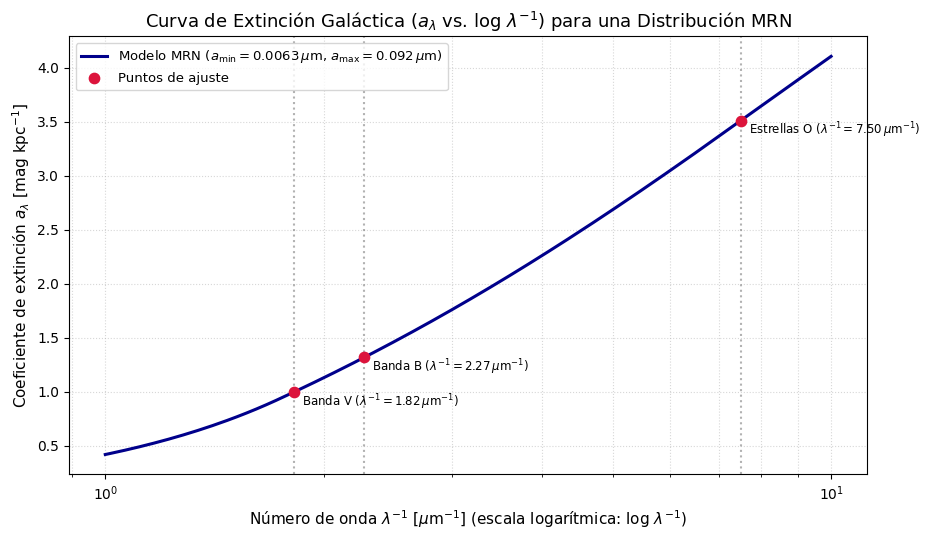

In [21]:
# Curva de extinción: a_lambda vs. log(lambda^-1) para lambda entre 100 nm y 1000 nm
longitudes_um = np.logspace(np.log10(0.1), np.log10(1.0), 150)  # 0.1 um (100 nm) a 1.0 um (1000 nm)
inv_lambda = 1.0 / longitudes_um  # lambda^-1 en um^-1 (de 1 a 10 um^-1)

extincion = np.array([
    coeficiente_extincion(lam, a_min_opt, a_max_opt)
    for lam in longitudes_um
])

plt.figure(figsize=(9.5, 5.5))
plt.plot(inv_lambda, extincion, color='darkblue', linewidth=2.2,
         label=f'Modelo MRN ($a_{{\min}}={a_min_opt:.4f}\,\mu$m, $a_{{\max}}={a_max_opt:.3f}\,\mu$m)')

# Puntos de referencia (V, B, O*)
inv_refs = [1.0 / lambda_V, 1.0 / lambda_B, 1.0 / lambda_O_um]
ext_refs = [a_V_opt, a_B_opt, a_O_opt]
etiquetas_refs = [
    f'Banda V ($\lambda^{{-1}}={1/lambda_V:.2f}\,\mu$m$^{{-1}}$)',
    f'Banda B ($\lambda^{{-1}}={1/lambda_B:.2f}\,\mu$m$^{{-1}}$)',
    f'Estrellas O ($\lambda^{{-1}}={1/lambda_O_um:.2f}\,\mu$m$^{{-1}}$)'
]

plt.scatter(inv_refs, ext_refs, color='crimson', s=55, zorder=5, label='Puntos de ajuste')
for inv_l, a_val, txt in zip(inv_refs, ext_refs, etiquetas_refs):
    plt.axvline(inv_l, color='gray', linestyle=':', alpha=0.6)
    plt.annotate(txt, (inv_l, a_val), textcoords='offset points', xytext=(6, -10), fontsize=8.5)

plt.xscale('log')  # Eje horizontal en log(lambda^-1)
plt.xlabel(r'Número de onda $\lambda^{-1}$ [$\mu$m$^{-1}$] (escala logarítmica: $\log\,\lambda^{-1}$)', fontsize=11)
plt.ylabel(r'Coeficiente de extinción $a_\lambda$ [mag kpc$^{-1}$]', fontsize=11)
plt.title('Curva de Extinción Galáctica ($a_\lambda$ vs. $\log\,\lambda^{-1}$) para una Distribución MRN', fontsize=13)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.legend(fontsize=9.5, loc='upper left')
plt.tight_layout()
plt.show()

El ajuste por mínimos cuadrados encuentra $a_{\min} \approx 6.3 \times 10^{-3}\,\mu\text{m}$ y $a_{\max} \approx 0.092\,\mu\text{m}$, valores que coinciden con lo esperado, y reproducen simultáneamente $a_V \approx 1.00\text{ mag kpc}^{-1}$, $R_V \approx 3.11$ y $a_{\lambda_{O*}} \approx 3.51\text{ mag kpc}^{-1}$.

### ¿Cómo gobierna cada rango de tamaños la curva de extinción?

Para comprender físicamente los límites de tamaño obtenidos en nuestro ajuste ($a_{\min} \approx 0.006\ \mu\text{m}$ y $a_{\max} \approx 0.09\ \mu\text{m}$), resulta útil analizar cómo la fuerte pendiente de la distribución MRN ($dn_d/da \propto a^{-3.5}$) distribuye el área superficial y el volumen de los granos en el medio interestelar:

* **Granos pequeños (Dominancia en el Ultravioleta):**  
  Debido al exponente negativo $-3.5$, la densidad numérica de granos es extremadamente sensible al tamaño; los granos nanométricos son órdenes de magnitud más abundantes que los grandes. Aunque cada grano pequeño individual aporta muy poca sección eficaz, el **área superficial integrada** de esta parte de la población es inmensa.
  Dado que la sección eficaz en el régimen donde $\lambda \sim 2\pi a$ es proporcional al área geométrica, esta gigantesca superficie colectiva bloquea de manera muy eficiente la radiación de longitud de onda corta. Por lo tanto, los granos cercanos a $a_{\min}$ son los que **gobiernan y producen la empinada pendiente de la curva de extinción en el rango UV**.

* **Granos grandes (Dominancia en el Óptico y control de $R_V$):**  
  Al movernos hacia longitudes de onda del rango óptico (como las bandas B y V, con $\lambda \sim 0.44\text{--}0.55\ \mu\text{m}$), la condición $\lambda \gg 2\pi a$ se cumple para los granos más pequeños. En este régimen (Rayleigh), su eficiencia de extinción cae drásticamente como $Q_\lambda \propto (a/\lambda)^{1.45}$, volviéndose prácticamente transparentes a la luz visible.
  En consecuencia, la extinción en el óptico depende casi exclusivamente de la fracción de granos de mayor tamaño en la distribución (cercanos al límite de corte superior $a_{\max}$). Como la diferencia entre la extinción en la banda B y en la V define el enrojecimiento, el parámetro **$a_{\max}$ es el factor físico que determina el valor del parámetro de extinción selectiva $R_V = a_V / (a_B - a_V)$**. El valor estándar observado de $R_V \approx 3.1$ requiere un límite superior de tamaño de granos en torno a $0.1\ \mu\text{m}$.

## Declaración de uso ético de IA

En la elaboración de este proyecto se utilizó el asistente de inteligencia artificial Gemini en tres formas diferentes: Gemini Notebook lm como herramienta de estudio teórico y guía para el flujo de trabajo, basándose en los textos guías de clase; por otro lado, su versión implementada en Google Colab para corrección de errores y mejoras en gráficas, y por último, en su versión Plus de chat como apoyo para la revisión de la primera versión completa del trabajo, para evaluar estructura del código en Python, la depuración de conversiones de unidades y la verificación de la presentación de ecuaciones en LaTeX.
Todo el planteamiento físico, la implementación de las simulaciones, la ejecución de los cálculos y el análisis de los resultados fueron comprendidos, validados y redactados por mi autoría.